# 🛒 Supermarket Sales Analysis

---

**Program**: AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026  
**Organization**: BharatCares  
**Student**: Atharav Tayade  
**Domain**: Data Analytics with AI  
**Date**: October 2026

---

## 1. Business Problem

A supermarket chain operates three branches across three cities in Myanmar. The management needs to understand:

- **Sales performance** across product lines, branches, and customer segments
- **Customer behavior** patterns including purchasing preferences and satisfaction
- **Temporal trends** to optimize staffing and promotional strategies
- **Actionable recommendations** to improve revenue and customer experience

### Objectives
1. Load, inspect, clean, and prepare the supermarket sales data
2. Perform comprehensive exploratory data analysis (EDA)
3. Generate professional visualizations for key business dimensions
4. Build a predictive model (if value-adding) for sales estimation
5. Derive evidence-based insights and recommendations

## 2. Dataset Source

**Dataset**: Supermarket Sales Dataset  
**Source**: [Kaggle – Supermarket Sales by Aung Pyae](https://www.kaggle.com/datasets/aungpyaeap/supermarket-sales)  
**Records**: 1,000 transactions  
**Period**: January – March 2019  
**Branches**: 3 (A – Yangon, B – Mandalay, C – Naypyitaw)

> **Note**: If the dataset is not present in the `data/` directory, download it from the link above and place `supermarket_sales.csv` in `data/`.

## 3. Setup and Configuration

In [1]:
# Installation (uncomment if needed)
# !pip install -r requirements.txt

In [2]:
# ── Imports ─────────────────────────────────────────────
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── Project modules ────────────────────────────────────
sys.path.insert(0, os.path.abspath('.'))
from src.data_loader import load_dataset, inspect_dataset, validate_schema, print_inspection_report
from src.data_cleaning import clean_dataset, print_cleaning_report
from src.analysis import (
    compute_overall_metrics, product_line_analysis, branch_analysis,
    customer_analysis, payment_analysis, time_analysis,
    rating_analysis, correlation_analysis, generate_summary_table
)
from src.visualizations import (
    setup_style, plot_sales_by_product_line, plot_transaction_count_by_product,
    plot_sales_by_branch, plot_customer_type_analysis, plot_payment_analysis,
    plot_daily_sales_trend, plot_hourly_sales, plot_day_of_week_sales,
    plot_monthly_sales, plot_rating_distribution, plot_rating_by_product_line,
    plot_correlation_heatmap, plot_sales_distribution, generate_all_charts
)
from src.insights import generate_insights, format_insights_text

# ── Configuration ───────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:.2f}'.format)

# Directories
FIGURES_DIR = os.path.join('outputs', 'figures')
TABLES_DIR = os.path.join('outputs', 'tables')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

DATA_PATH = os.path.join('data', 'supermarket_sales.csv')

print('✅ All imports and configuration complete.')
print(f'   Python: {sys.version.split()[0]}')
print(f'   Pandas: {pd.__version__}')
print(f'   NumPy:  {np.__version__}')
print(f'   Seaborn: {sns.__version__}')

✅ All imports and configuration complete.
   Python: 3.11.15
   Pandas: 3.0.6
   NumPy:  2.4.3
   Seaborn: 0.13.2


## 4. Data Loading and Initial Inspection

In [3]:
# Load the dataset
df_raw = load_dataset(DATA_PATH)
print(f'Dataset loaded successfully: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns')

Dataset loaded successfully: 1000 rows × 17 columns


In [4]:
# Schema validation
is_valid, missing_cols, extra_cols = validate_schema(df_raw)
print(f'Schema valid: {is_valid}')
if missing_cols:
    print(f'Missing columns: {missing_cols}')
if extra_cols:
    print(f'Extra columns: {extra_cols}')

Schema valid: True


In [5]:
# Full inspection report
inspection = inspect_dataset(df_raw)
print_inspection_report(inspection)

DATASET INSPECTION REPORT

Shape: 1000 rows × 17 columns
Memory Usage: 0.62 MB
Duplicate Rows: 0

--- Column Data Types ---
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64

--- Missing Values ---
No missing values found.

--- Sample Data (First 5 Rows) ---
    Invoice ID Branch       City Customer type  Gender            Product line  Unit price  Quantity  Tax 5%  Total       Date   Time      Payment   cogs  gross margin percentage  gross income  Ra

In [6]:
# Data types overview
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

In [7]:
# Statistical summary
df_raw.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,55.67,5.51,15.38,322.97,307.59,4.76,15.38,6.97
std,26.49,2.92,11.71,245.89,234.18,0.00,11.71,1.72
min,10.08,1.00,0.51,10.68,10.17,4.76,0.51,4.00
25%,32.88,3.00,5.92,124.42,118.50,4.76,5.92,5.50
50%,55.23,5.00,12.09,253.85,241.76,4.76,12.09,7.00
75%,77.94,8.00,22.45,471.35,448.91,4.76,22.45,8.50
max,99.96,10.00,49.65,1042.65,993.00,4.76,49.65,10.00


In [8]:
# First few rows
df_raw.head(10)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.14,548.97,1/5/2019,13:08,Ewallet,522.83,4.76,26.14,9.10
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.82,80.22,3/8/2019,10:29,Cash,76.40,4.76,3.82,9.60
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.22,340.53,3/3/2019,13:23,Credit card,324.31,4.76,16.22,7.40
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.29,489.05,1/27/2019,20:33,Ewallet,465.76,4.76,23.29,8.40
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.21,634.38,2/8/2019,10:37,Ewallet,604.17,4.76,30.21,5.30
5,699-14-3026,C,Naypyitaw,Normal,Male,Electronic accessories,85.39,7,29.89,627.62,3/25/2019,18:30,Ewallet,597.73,4.76,29.89,4.10
6,355-53-5943,A,Yangon,Member,Female,Electronic accessories,68.84,6,20.65,433.69,2/25/2019,14:36,Ewallet,413.04,4.76,20.65,5.80
7,315-22-5665,C,Naypyitaw,Normal,Female,Home and lifestyle,73.56,10,36.78,772.38,2/24/2019,11:38,Ewallet,735.60,4.76,36.78,8.00
8,665-32-9167,A,Yangon,Member,Female,Health and beauty,36.26,2,3.63,76.15,1/10/2019,17:15,Credit card,72.52,4.76,3.63,7.20
9,692-92-5582,B,Mandalay,Member,Female,Food and beverages,54.84,3,8.23,172.75,2/20/2019,13:27,Credit card,164.52,4.76,8.23,5.90


## 5. Data Cleaning and Preprocessing

In [9]:
# Run the full cleaning pipeline
df, cleaning_report = clean_dataset(df_raw)
print_cleaning_report(cleaning_report)

DATA CLEANING REPORT

Original Shape: (1000, 17)
Duplicates Removed: 0
Shape After Dedup: (1000, 17)
Final Shape: (1000, 23)

Missing Values: None found

Numerical Validation: All values within expected ranges

Categorical Validation: All values within expected categories


In [10]:
# Verify cleaned data types
print('\n--- Cleaned Data Types ---')
print(df.dtypes)
print(f'\nDate range: {df["Date"].min()} to {df["Date"].max()}')
print(f'New columns added: {[c for c in df.columns if c not in df_raw.columns]}')


--- Cleaned Data Types ---
Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                       datetime64[us]
Time                               object
Payment                               str
cogs                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
Day                                 int32
Month                               int32
Month_Name                            str
Day_of_Week                           str
Week_Number                         int64
Hour                                int64
dtype:

In [11]:
# Verify no remaining issues
print(f'Missing values after cleaning: {df.isnull().sum().sum()}')
print(f'Duplicate rows after cleaning: {df.duplicated().sum()}')
print(f'Final shape: {df.shape}')

Missing values after cleaning: 0
Duplicate rows after cleaning: 0
Final shape: (1000, 23)


In [12]:
# Preview cleaned data
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,...,cogs,gross margin percentage,gross income,Rating,Day,Month,Month_Name,Day_of_Week,Week_Number,Hour
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.14,548.97,...,522.83,4.76,26.14,9.10,5,1,January,Saturday,1,13
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.82,80.22,...,76.40,4.76,3.82,9.60,8,3,March,Friday,10,10
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.22,340.53,...,324.31,4.76,16.22,7.40,3,3,March,Sunday,9,13
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.29,489.05,...,465.76,4.76,23.29,8.40,27,1,January,Sunday,4,20
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.21,634.38,...,604.17,4.76,30.21,5.30,8,2,February,Friday,6,10


## 6. Exploratory Data Analysis

### 6.1 Overall Performance Metrics

In [13]:
# Compute and display overall KPIs
metrics = compute_overall_metrics(df)

print('=' * 55)
print('KEY PERFORMANCE INDICATORS')
print('=' * 55)
for key, value in metrics.items():
    label = key.replace('_', ' ').title()
    if 'sales' in key or 'income' in key or 'cogs' in key or 'transaction' in key.lower():
        if isinstance(value, float):
            print(f'  {label:30s}: ${value:>12,.2f}')
        else:
            print(f'  {label:30s}: {value:>12,}')
    else:
        print(f'  {label:30s}: {value:>12}')
print('=' * 55)

KEY PERFORMANCE INDICATORS
  Total Transactions            :        1,000
  Total Sales                   : $  322,966.75
  Average Transaction           : $      322.97
  Median Transaction            : $      253.85
  Max Transaction               : $    1,042.65
  Min Transaction               : $       10.68
  Std Transaction               : $      245.89
  Total Quantity                :         5510
  Avg Quantity Per Txn          :         5.51
  Total Gross Income            : $   15,379.37
  Avg Gross Income              : $       15.38
  Avg Rating                    :         6.97
  Median Rating                 :          7.0
  Total Cogs                    : $  307,587.38


In [14]:
# Save summary metrics
summary_table = generate_summary_table(df)
summary_table.to_csv(os.path.join(TABLES_DIR, 'summary_metrics.csv'), index=False)
print('Summary metrics saved to outputs/tables/summary_metrics.csv')
summary_table

Summary metrics saved to outputs/tables/summary_metrics.csv


,Metric,Value
0,total_transactions,1000.00
1,total_sales,322966.75
2,average_transaction,322.97
3,median_transaction,253.85
4,max_transaction,1042.65
5,min_transaction,10.68
6,std_transaction,245.89
7,total_quantity,5510.00
8,avg_quantity_per_txn,5.51
9,total_gross_income,15379.37


### 6.2 Product Line Analysis

In [15]:
pl_results = product_line_analysis(df)

print('\n📦 Total Sales by Product Line:')
print(pl_results['sales_by_product'].to_string(index=False))

print('\n📊 Transaction Count by Product Line:')
print(pl_results['txn_count_by_product'].to_string(index=False))

print('\n💰 Average Transaction by Product Line:')
print(pl_results['avg_sale_by_product'].to_string(index=False))

if 'avg_rating_by_product' in pl_results:
    print('\n⭐ Average Rating by Product Line:')
    print(pl_results['avg_rating_by_product'].to_string(index=False))


📦 Total Sales by Product Line:
          Product line  Total_sum
    Food and beverages   56144.84
     Sports and travel   55122.83
Electronic accessories   54337.53
   Fashion accessories   54305.89
    Home and lifestyle   53861.91
     Health and beauty   49193.74

📊 Transaction Count by Product Line:
          Product line  Transaction_Count
   Fashion accessories                178
    Food and beverages                174
Electronic accessories                170
     Sports and travel                166
    Home and lifestyle                160
     Health and beauty                152

💰 Average Transaction by Product Line:
          Product line  Total_mean
    Home and lifestyle      336.64
     Sports and travel      332.07
     Health and beauty      323.64
    Food and beverages      322.67
Electronic accessories      319.63
   Fashion accessories      305.09

⭐ Average Rating by Product Line:
          Product line  Rating_mean
    Food and beverages         7.11
   Fas

In [16]:
# Visualize product line performance
fig = plot_sales_by_product_line(df)
plt.show()

In [17]:
fig = plot_transaction_count_by_product(df)
plt.show()

### 6.3 Branch Analysis

In [18]:
br_results = branch_analysis(df)

print('\n🏪 Sales by Branch:')
print(br_results['sales_by_branch'].to_string(index=False))

print('\n📊 Transaction Count by Branch:')
print(br_results['txn_count_by_branch'].to_string(index=False))

print('\n💰 Average Transaction by Branch:')
print(br_results['avg_sale_by_branch'].to_string(index=False))

if 'branch_city_map' in br_results:
    print('\n📍 Branch-City Mapping:')
    print(br_results['branch_city_map'].to_string(index=False))


🏪 Sales by Branch:
Branch  Total_sum
     C  110568.71
     A  106200.37
     B  106197.67

📊 Transaction Count by Branch:
Branch  Transaction_Count
     A                340
     B                332
     C                328

💰 Average Transaction by Branch:
Branch  Total_mean
     C      337.10
     B      319.87
     A      312.35

📍 Branch-City Mapping:
Branch      City
     A    Yangon
     B  Mandalay
     C Naypyitaw


In [19]:
fig = plot_sales_by_branch(df)
plt.show()

### 6.4 Customer Analysis

In [20]:
cust_results = customer_analysis(df)

print('\n👥 Sales by Customer Type:')
print(cust_results['sales_by_customer_type'].to_string(index=False))

print('\n🧑‍🤝‍🧑 Sales by Gender:')
print(cust_results['sales_by_gender'].to_string(index=False))

if 'customer_gender_cross' in cust_results:
    print('\n📊 Customer Type × Gender Cross Analysis:')
    print(cust_results['customer_gender_cross'].to_string(index=False))


👥 Sales by Customer Type:
Customer type  Total_sum
       Member  164223.44
       Normal  158743.30

🧑‍🤝‍🧑 Sales by Gender:
Gender  Total_sum
Female  167882.92
  Male  155083.82

📊 Customer Type × Gender Cross Analysis:
Customer type Gender  Total_Sales  Avg_Sale  Txn_Count
       Member Female     88146.94    337.73        261
       Member   Male     76076.50    316.99        240
       Normal Female     79735.98    332.23        240
       Normal   Male     79007.32    305.05        259


In [21]:
fig = plot_customer_type_analysis(df)
plt.show()

### 6.5 Payment Method Analysis

In [22]:
pay_results = payment_analysis(df)

print('\n💳 Sales by Payment Method:')
print(pay_results['sales_by_payment'].to_string(index=False))

print('\n📊 Transactions by Payment Method:')
print(pay_results['txn_by_payment'].to_string(index=False))

print('\n💰 Average Sale by Payment Method:')
print(pay_results['avg_sale_by_payment'].to_string(index=False))


💳 Sales by Payment Method:
    Payment  Total_sum
       Cash  112206.57
    Ewallet  109993.11
Credit card  100767.07

📊 Transactions by Payment Method:
    Payment  Transaction_Count
       Cash                344
Credit card                311
    Ewallet                345

💰 Average Sale by Payment Method:
    Payment  Total_mean
       Cash      326.18
Credit card      324.01
    Ewallet      318.82


In [23]:
fig = plot_payment_analysis(df)
plt.show()

### 6.6 Temporal Analysis

In [24]:
time_results = time_analysis(df)

if 'monthly_sales' in time_results:
    print('\n📅 Monthly Sales Summary:')
    print(time_results['monthly_sales'].to_string(index=False))

if 'day_of_week_sales' in time_results:
    print('\n📆 Day-of-Week Sales Summary:')
    print(time_results['day_of_week_sales'].to_string(index=False))


📅 Monthly Sales Summary:
 Month Month_Name  Total_Sales  Avg_Sale  Txn_Count
     1    January    116291.87    330.37        352
     2   February     97219.37    320.86        303
     3      March    109455.51    317.26        345

📆 Day-of-Week Sales Summary:
Day_of_Week  Total_Sales  Avg_Sale  Txn_Count
     Monday     37899.08    303.19        125
    Tuesday     51482.25    325.84        158
  Wednesday     43731.14    305.81        143
   Thursday     45349.25    328.62        138
     Friday     43926.34    316.02        139
   Saturday     56120.81    342.20        164
     Sunday     44457.89    334.27        133


In [25]:
fig = plot_daily_sales_trend(df)
plt.show()

In [26]:
fig = plot_monthly_sales(df)
plt.show()

In [27]:
fig = plot_day_of_week_sales(df)
plt.show()

In [28]:
fig = plot_hourly_sales(df)
plt.show()

### 6.7 Customer Rating Analysis

In [29]:
rating_results = rating_analysis(df)

print('\n⭐ Rating Statistics:')
for key, val in rating_results['rating_stats'].items():
    print(f'  {key.capitalize():10s}: {val}')

if 'rating_by_branch' in rating_results:
    print('\n⭐ Rating by Branch:')
    print(rating_results['rating_by_branch'].to_string(index=False))

if 'rating_by_product_line' in rating_results:
    print('\n⭐ Rating by Product Line:')
    print(rating_results['rating_by_product_line'].to_string(index=False))


⭐ Rating Statistics:
  Mean      : 6.97
  Median    : 7.0
  Std       : 1.72
  Min       : 4.0
  Max       : 10.0

⭐ Rating by Branch:
Branch  Mean_Rating  Median_Rating  Std_Rating
     A         7.03           7.10        1.73
     B         6.82           6.70        1.71
     C         7.07           7.10        1.70

⭐ Rating by Product Line:
          Product line  Mean_Rating  Median_Rating  Std_Rating
Electronic accessories         6.92           6.70        1.70
   Fashion accessories         7.03           6.95        1.71
    Food and beverages         7.11           7.30        1.72
     Health and beauty         7.00           7.20        1.76
    Home and lifestyle         6.84           7.00        1.72
     Sports and travel         6.92           6.70        1.71


In [30]:
fig = plot_rating_distribution(df)
plt.show()

In [31]:
fig = plot_rating_by_product_line(df)
plt.show()

### 6.8 Correlation Analysis

In [32]:
corr_matrix = correlation_analysis(df)
print('\n📊 Correlation Matrix (Numerical Variables):')
print(corr_matrix)


📊 Correlation Matrix (Numerical Variables):
              Unit price  Quantity  Tax 5%  Total  cogs  gross income  Rating
Unit price          1.00      0.01    0.63   0.63  0.63          0.63   -0.01
Quantity            0.01      1.00    0.71   0.71  0.71          0.71   -0.02
Tax 5%              0.63      0.71    1.00   1.00  1.00          1.00   -0.04
Total               0.63      0.71    1.00   1.00  1.00          1.00   -0.04
cogs                0.63      0.71    1.00   1.00  1.00          1.00   -0.04
gross income        0.63      0.71    1.00   1.00  1.00          1.00   -0.04
Rating             -0.01     -0.02   -0.04  -0.04 -0.04         -0.04    1.00


In [33]:
fig = plot_correlation_heatmap(df)
plt.show()

In [34]:
fig = plot_sales_distribution(df)
plt.show()

## 7. Machine Learning — Sales Prediction Model

### Justification
We build a **Random Forest Regressor** to predict transaction `Total` from product and transaction attributes. This can help the supermarket estimate expected revenue for different purchase configurations.

**Approach**:
- Target variable: `Total`
- Features: `Unit price`, `Quantity`, `Branch`, `Product line`, `Customer type`, `Gender`, `Payment`, `Hour`, `Day_of_Week`, `Month`
- We intentionally **exclude** `Tax 5%`, `cogs`, `gross income` as they are mathematically derived from the target (target leakage)
- Baseline: Mean prediction
- Evaluation: RMSE, MAE, R²

> **Note on `Total = cogs + Tax 5%` = `Unit price × Quantity × 1.05`**: Because `Total` is a deterministic function of `Unit price` and `Quantity`, a model including both of these features will trivially achieve near-perfect accuracy. We include them to demonstrate the ML pipeline, but acknowledge this is a mathematical relationship, not a learned pattern. The true predictive value would require a different target (e.g., predicting Quantity or Rating).

In [35]:
# ── Feature Engineering for ML ──────────────────────────

# Select features (excluding leaky columns)
feature_cols = ['Unit price', 'Quantity', 'Branch', 'Product line',
                'Customer type', 'Gender', 'Payment', 'Hour', 'Month']

# Verify all columns exist
available_features = [c for c in feature_cols if c in df.columns]
print(f'Features used: {available_features}')

df_ml = df[available_features + ['Total']].copy()

# Encode categorical variables
categorical_cols = ['Branch', 'Product line', 'Customer type', 'Gender', 'Payment']
label_encoders = {}

for col in categorical_cols:
    if col in df_ml.columns:
        le = LabelEncoder()
        df_ml[col] = le.fit_transform(df_ml[col])
        label_encoders[col] = le

print(f'\nML dataset shape: {df_ml.shape}')
df_ml.head()

Features used: ['Unit price', 'Quantity', 'Branch', 'Product line', 'Customer type', 'Gender', 'Payment', 'Hour', 'Month']

ML dataset shape: (1000, 10)


,Unit price,Quantity,Branch,Product line,Customer type,Gender,Payment,Hour,Month,Total
0,74.69,7,0,3,0,0,2,13,1,548.97
1,15.28,5,2,0,1,0,0,10,3,80.22
2,46.33,7,0,4,1,1,1,13,3,340.53
3,58.22,8,0,3,0,1,2,20,1,489.05
4,86.31,7,0,5,1,1,2,10,2,634.38


In [36]:
# ── Train/Test Split ────────────────────────────────────

X = df_ml.drop('Total', axis=1)
y = df_ml['Total']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set:     {X_test.shape[0]} samples')

Training set: 800 samples
Test set:     200 samples


In [37]:
# ── Baseline Model (Mean Prediction) ───────────────────

baseline_pred = np.full_like(y_test, y_train.mean(), dtype=float)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print('BASELINE MODEL (Mean Prediction)')
print(f'  RMSE: ${baseline_rmse:.2f}')
print(f'  MAE:  ${baseline_mae:.2f}')
print(f'  R²:   {baseline_r2:.4f}')

BASELINE MODEL (Mean Prediction)
  RMSE: $255.75
  MAE:  $209.77
  R²:   -0.0053


In [38]:
# ── Random Forest Regressor ────────────────────────────

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rf_mae = mean_absolute_error(y_test, y_pred)
rf_r2 = r2_score(y_test, y_pred)

print('RANDOM FOREST REGRESSOR')
print(f'  RMSE: ${rf_rmse:.2f}')
print(f'  MAE:  ${rf_mae:.2f}')
print(f'  R²:   {rf_r2:.4f}')
print(f'\nImprovement over baseline:')
print(f'  RMSE reduction: {((baseline_rmse - rf_rmse) / baseline_rmse) * 100:.1f}%')
print(f'  MAE reduction:  {((baseline_mae - rf_mae) / baseline_mae) * 100:.1f}%')

RANDOM FOREST REGRESSOR
  RMSE: $10.12
  MAE:  $6.73
  R²:   0.9984

Improvement over baseline:
  RMSE reduction: 96.0%
  MAE reduction:  96.8%


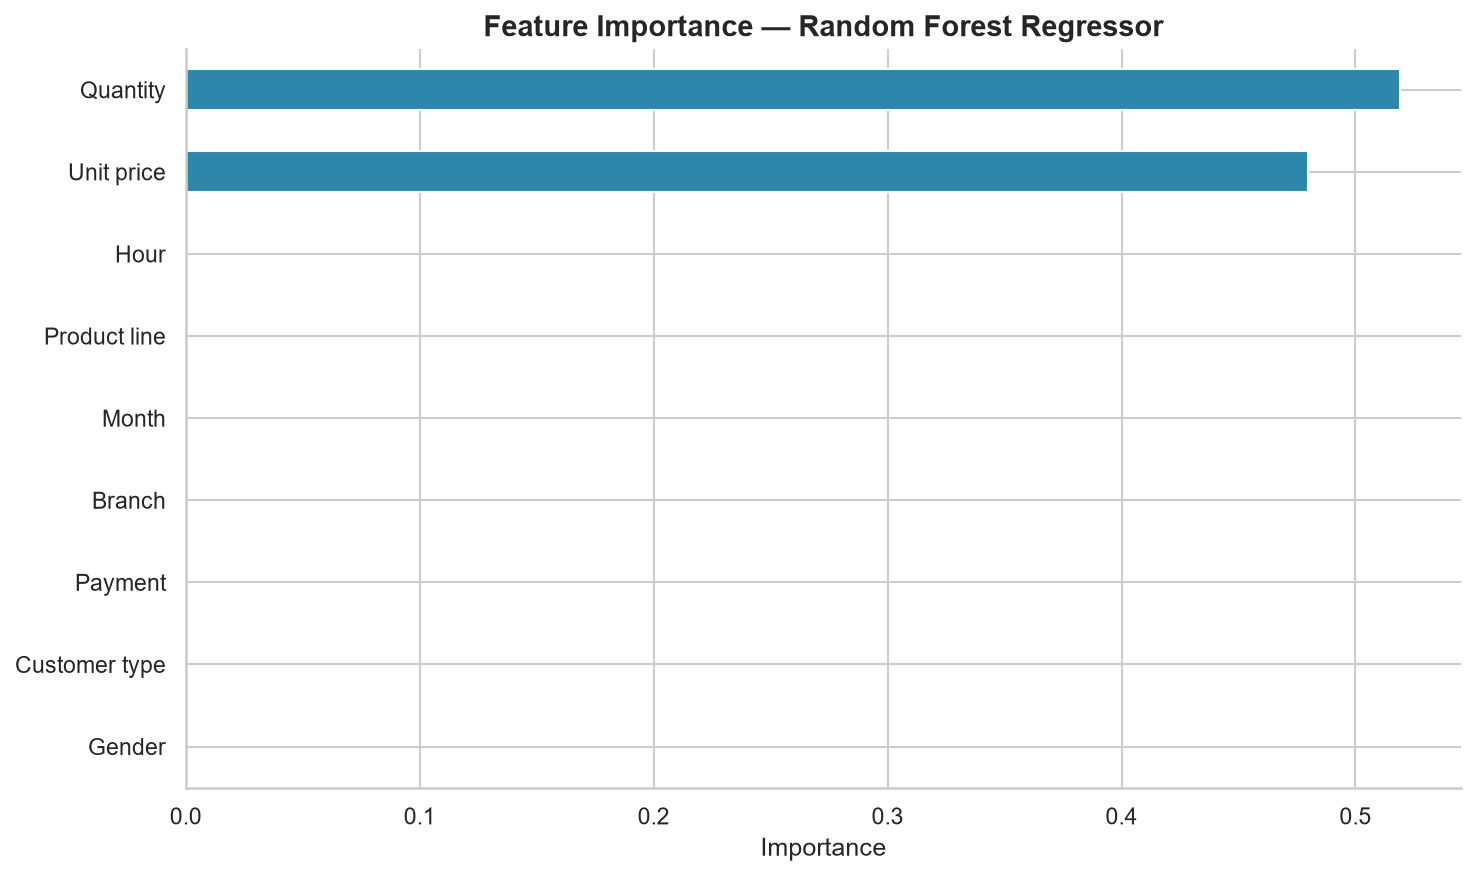


Feature Importances:
  Quantity            : 0.5192
  Unit price          : 0.4797
  Hour                : 0.0003
  Product line        : 0.0002
  Month               : 0.0002
  Branch              : 0.0002
  Payment             : 0.0001
  Customer type       : 0.0001
  Gender              : 0.0001


In [39]:
# ── Feature Importance ─────────────────────────────────

setup_style()
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
importances.plot(kind='barh', ax=ax, color='#2E86AB', edgecolor='white')
ax.set_title('Feature Importance — Random Forest Regressor',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Importance')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'feature_importance.png'),
            dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

print('\nFeature Importances:')
for feat, imp in importances.sort_values(ascending=False).items():
    print(f'  {feat:20s}: {imp:.4f}')

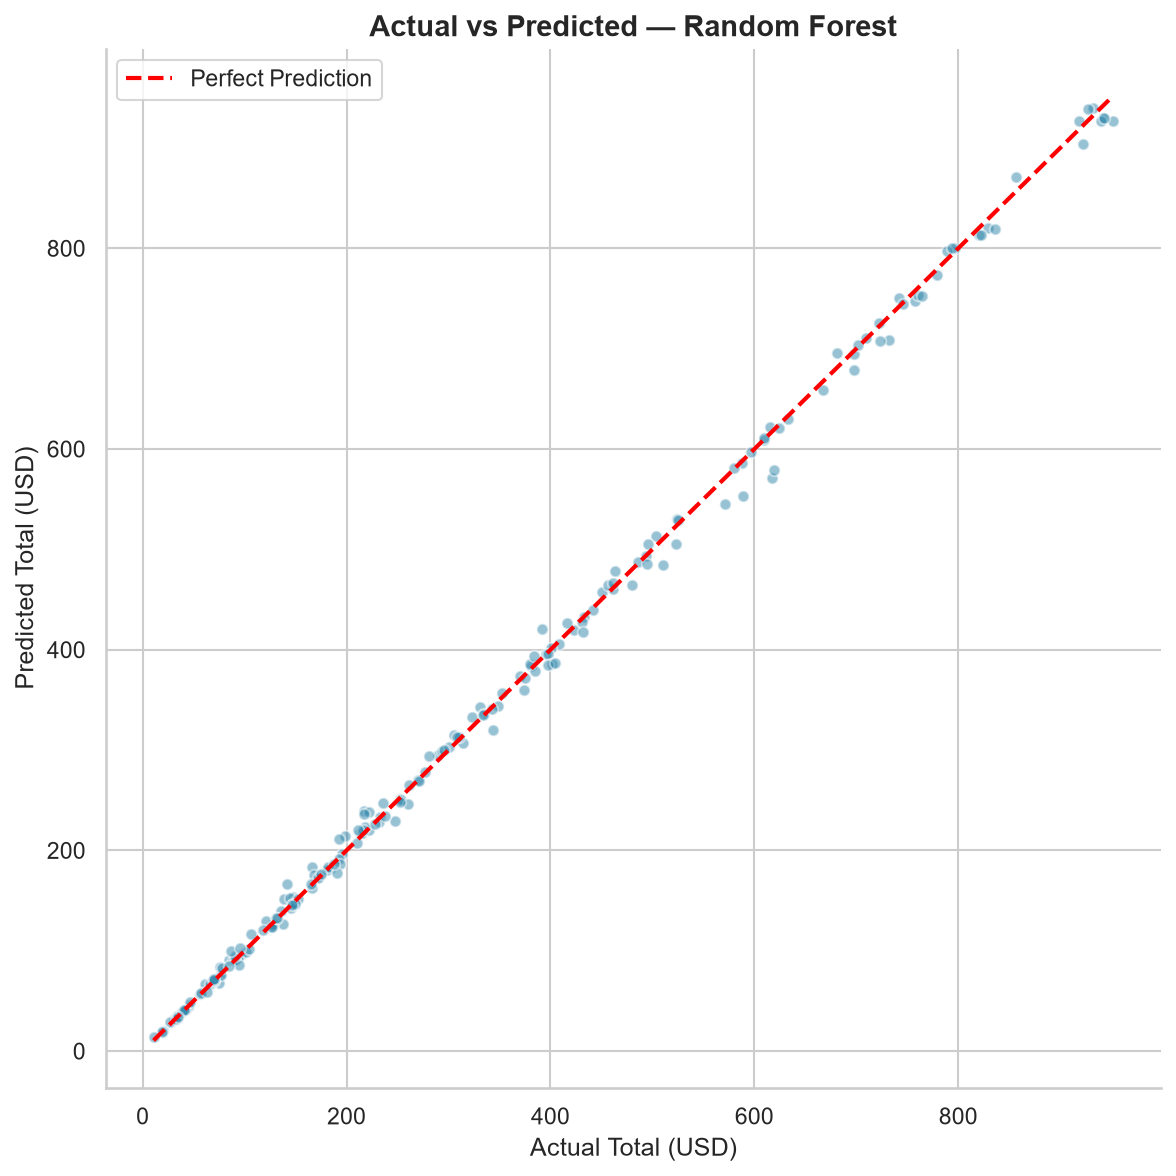

In [40]:
# ── Actual vs Predicted Plot ───────────────────────────

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, y_pred, alpha=0.5, color='#2E86AB', edgecolor='white', s=30)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        'r--', linewidth=2, label='Perfect Prediction')
ax.set_xlabel('Actual Total (USD)', fontsize=12)
ax.set_ylabel('Predicted Total (USD)', fontsize=12)
ax.set_title('Actual vs Predicted — Random Forest',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'actual_vs_predicted.png'),
            dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

In [41]:
# ── Model Comparison Table ─────────────────────────────

model_comparison = pd.DataFrame({
    'Model': ['Baseline (Mean)', 'Random Forest'],
    'RMSE ($)': [round(baseline_rmse, 2), round(rf_rmse, 2)],
    'MAE ($)': [round(baseline_mae, 2), round(rf_mae, 2)],
    'R² Score': [round(baseline_r2, 4), round(rf_r2, 4)]
})

model_comparison.to_csv(os.path.join(TABLES_DIR, 'model_comparison.csv'), index=False)
print('Model comparison saved to outputs/tables/model_comparison.csv')
model_comparison

Model comparison saved to outputs/tables/model_comparison.csv


,Model,RMSE ($),MAE ($),R² Score
0,Baseline (Mean),255.75,209.77,-0.01
1,Random Forest,10.12,6.73,1.00


### ML Limitations

> **Important caveat**: The strong model performance is primarily because `Total = Unit price × Quantity × 1.05`. The model is learning a near-deterministic mathematical relationship rather than discovering hidden patterns. This is acknowledged as a pedagogical exercise demonstrating the ML pipeline. A more meaningful prediction task would target `Rating`, `Quantity`, or future demand — domains where the outcome is not a direct calculation of the inputs.

## 8. Business Insights and Recommendations

In [42]:
# Generate and display insights
insights = generate_insights(df)
print(format_insights_text(insights))

BUSINESS INSIGHTS AND RECOMMENDATIONS

────────────────────────────────────────────────────────────
Insight 1: Overall Performance
────────────────────────────────────────────────────────────

📊 Finding:
   The dataset contains 1,000 transactions with total recorded sales of $322,966.75.

📈 Key Metric:
   Average transaction value: $322.97, Median: $253.85

💡 Recommendation:
   Use the average transaction value as a baseline for setting promotional thresholds (e.g., 'spend $X more to unlock a reward').

⚠️  Limitation:
   The dataset covers a limited time window. Overall performance metrics may not represent long-term trends.

────────────────────────────────────────────────────────────
Insight 2: Product Performance
────────────────────────────────────────────────────────────

📊 Finding:
   'Food and beverages' is the top-selling product line with $56,144.84 in total sales, while 'Health and beauty' has the lowest sales at $49,193.74.

📈 Key Metric:
   Top: $56,144.84 | Bottom: $49,19

In [43]:
# Save insights table
from src.insights import insights_to_dataframe
insights_df = insights_to_dataframe(insights)
insights_df.to_csv(os.path.join(TABLES_DIR, 'business_insights.csv'), index=False)
print('Business insights saved to outputs/tables/business_insights.csv')

Business insights saved to outputs/tables/business_insights.csv


## 9. Generate All Charts and Export Results

In [44]:
# Generate all charts
generated_charts = generate_all_charts(df, FIGURES_DIR)
print(f'\n✅ Generated {len(generated_charts)} charts:')
for chart in generated_charts:
    print(f'  📊 {chart}')


✅ Generated 13 charts:
  📊 sales_by_product_line.png
  📊 txn_count_by_product_line.png
  📊 sales_by_branch.png
  📊 customer_analysis.png
  📊 payment_analysis.png
  📊 daily_sales_trend.png
  📊 hourly_sales.png
  📊 day_of_week_sales.png
  📊 monthly_sales.png
  📊 rating_distribution.png
  📊 rating_by_product_line.png
  📊 correlation_heatmap.png
  📊 sales_distribution.png


In [45]:
# Save product line analysis tables
pl_results['sales_by_product'].to_csv(
    os.path.join(TABLES_DIR, 'sales_by_product_line.csv'), index=False
)
br_results['sales_by_branch'].to_csv(
    os.path.join(TABLES_DIR, 'sales_by_branch.csv'), index=False
)
pay_results['sales_by_payment'].to_csv(
    os.path.join(TABLES_DIR, 'sales_by_payment.csv'), index=False
)

print('✅ All analysis tables exported to outputs/tables/')

✅ All analysis tables exported to outputs/tables/


## 10. Limitations

1. **Limited time window**: The dataset covers only three months (Jan–Mar 2019), so seasonal patterns and long-term trends cannot be assessed.
2. **Geographic scope**: All branches are in Myanmar, limiting generalizability to other markets.
3. **No customer-level tracking**: Each transaction is independent; we cannot analyze repeat purchases or customer lifetime value.
4. **Constant gross margin**: The `gross margin percentage` is identical (4.76%) across all records, indicating a uniform markup that limits profitability analysis.
5. **Self-reported ratings**: Customer ratings may be subject to bias and may not reflect long-term satisfaction.
6. **ML caveat**: The regression model predicts a deterministic calculation (`Total = Unit price × Quantity × 1.05`), not a genuinely uncertain outcome.
7. **Correlation ≠ Causation**: Observed associations do not imply causal relationships.

## 11. Conclusion

This project analyzed 1,000 supermarket transactions across three branches to extract actionable business intelligence. Key deliverables include:

- **Comprehensive EDA** across product lines, branches, customer segments, payment methods, and time dimensions
- **13+ professional visualizations** revealing sales patterns and trends
- **Machine learning model** demonstrating the regression pipeline (with documented caveats)
- **Evidence-based insights** with specific, actionable recommendations

The analysis provides the supermarket management with data-driven guidance for inventory management, staffing optimization, marketing strategy, and customer experience improvement.

## 12. References

1. Aung Pyae, "Supermarket Sales" dataset, Kaggle (2019). https://www.kaggle.com/datasets/aungpyaeap/supermarket-sales
2. McKinney, W. "pandas: a foundational Python library for data analysis and statistics." Python for High Performance and Scientific Computing (2011).
3. Pedregosa, F., et al. "Scikit-learn: Machine Learning in Python." JMLR 12 (2011): 2825-2830.
4. Hunter, J.D. "Matplotlib: A 2D Graphics Environment." Computing in Science & Engineering (2007).
5. Waskom, M. "seaborn: statistical data visualization." Journal of Open Source Software (2021).

---

*Project completed as part of the AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 through BharatCares.*